In [1]:
from pathlib import Path
from collections import Counter
import importlib.util
import subprocess
import sys

REQUIRED_PACKAGES = {
    "xgboost": "xgboost",
    "lightgbm": "lightgbm",
    "catboost": "catboost",
}

for package, import_name in REQUIRED_PACKAGES.items():
    if importlib.util.find_spec(import_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")


## Load the competition data

The canonical project layout is `data/raw`. A small fallback supports the three CSVs currently located at the repository root, including the downloaded `(1)` suffixes. This keeps paths explicit instead of silently reading an unrelated file.


In [6]:
from pathlib import Path
import pandas as pd

def find_project_root(marker=".git", start=None):
    """Walk up from the current directory until we find the repo root
    (identified by the presence of a .git folder)."""
    current = Path(start or Path.cwd()).resolve()
    for parent in [current, *current.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(
        f"Could not locate project root (no {marker} found above {current})."
    )

PROJECT_DIR = find_project_root()
DATA_DIR = PROJECT_DIR / "data" / "raw"
SUBMISSION_DIR = PROJECT_DIR / "submissions"
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

def resolve_data_file(canonical_name, fallback_name):
    """Prefer data/raw; retain compatibility with the current root-level download."""
    canonical_path = DATA_DIR / canonical_name
    fallback_path = DATA_DIR / fallback_name  # fixed: was PROJECT_DIR
    if canonical_path.exists():
        return canonical_path
    if fallback_path.exists():
        print(f"Using fallback file: {fallback_path.name}")
        return fallback_path
    raise FileNotFoundError(
        f"Could not find {canonical_path} or {fallback_path}. "
        "Place the competition CSVs in data/raw."
    )

TRAIN_PATH = resolve_data_file("train.csv", "train (1).csv")
TEST_PATH = resolve_data_file("test.csv", "test (1).csv")
SAMPLE_SUBMISSION_PATH = resolve_data_file(
    "sample_submission.csv", "sample_submission.csv"
)

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_SUBMISSION_PATH)

test_passenger_ids = test_df["PassengerId"].copy()
train_df["is_train"] = True
test_df["is_train"] = False
combined_raw = pd.concat([train_df, test_df], ignore_index=True, sort=False)

print(f"Project root: {PROJECT_DIR}")
print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Combined shape: {combined_raw.shape}")
display(sample_submission.head())

Using fallback file: train (1).csv
Using fallback file: test (1).csv
Project root: /workspaces/alpha-centauri-rescue
Train shape: (8693, 15)
Test shape: (4277, 14)
Combined shape: (12970, 15)


,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,False
3,0021_01,False
4,0023_01,False


## Inspect missingness and the target

Missingness is shown before imputation so later choices are auditable. The target balance supplies the accuracy baseline: a model must materially improve on simply predicting the majority class.


,missing_values
CryoSleep,310
ShoppingMall,306
Cabin,299
VIP,296
Name,294
FoodCourt,289
HomePlanet,288
Spa,284
Destination,274
Age,270


,proportion
Transported,
True,0.503624
False,0.496376


Majority-class accuracy: 0.504


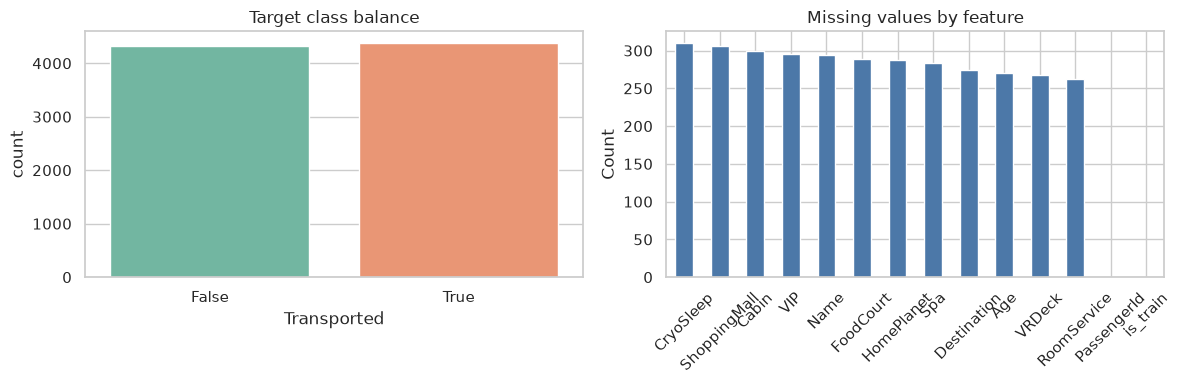

In [7]:
missing_counts = (
    combined_raw.drop(columns="Transported", errors="ignore")
    .isna()
    .sum()
    .sort_values(ascending=False)
)
display(missing_counts.to_frame("missing_values"))

target_balance = train_df["Transported"].value_counts(normalize=True).rename("proportion")
display(target_balance.to_frame())
print(f"Majority-class accuracy: {target_balance.max():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=train_df, x="Transported", ax=axes[0], palette="Set2", hue="Transported", legend=False)
axes[0].set_title("Target class balance")
axes[0].set_xlabel("Transported")

missing_counts.plot(kind="bar", ax=axes[1], color="#4C78A8")
axes[1].set_title("Missing values by feature")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## Explore age and amenity spending

Age and the five spending fields are the principal continuous inputs. Their distributions are plotted by the target to reveal signal, heavy skew, and values needing resilient median-based treatment.


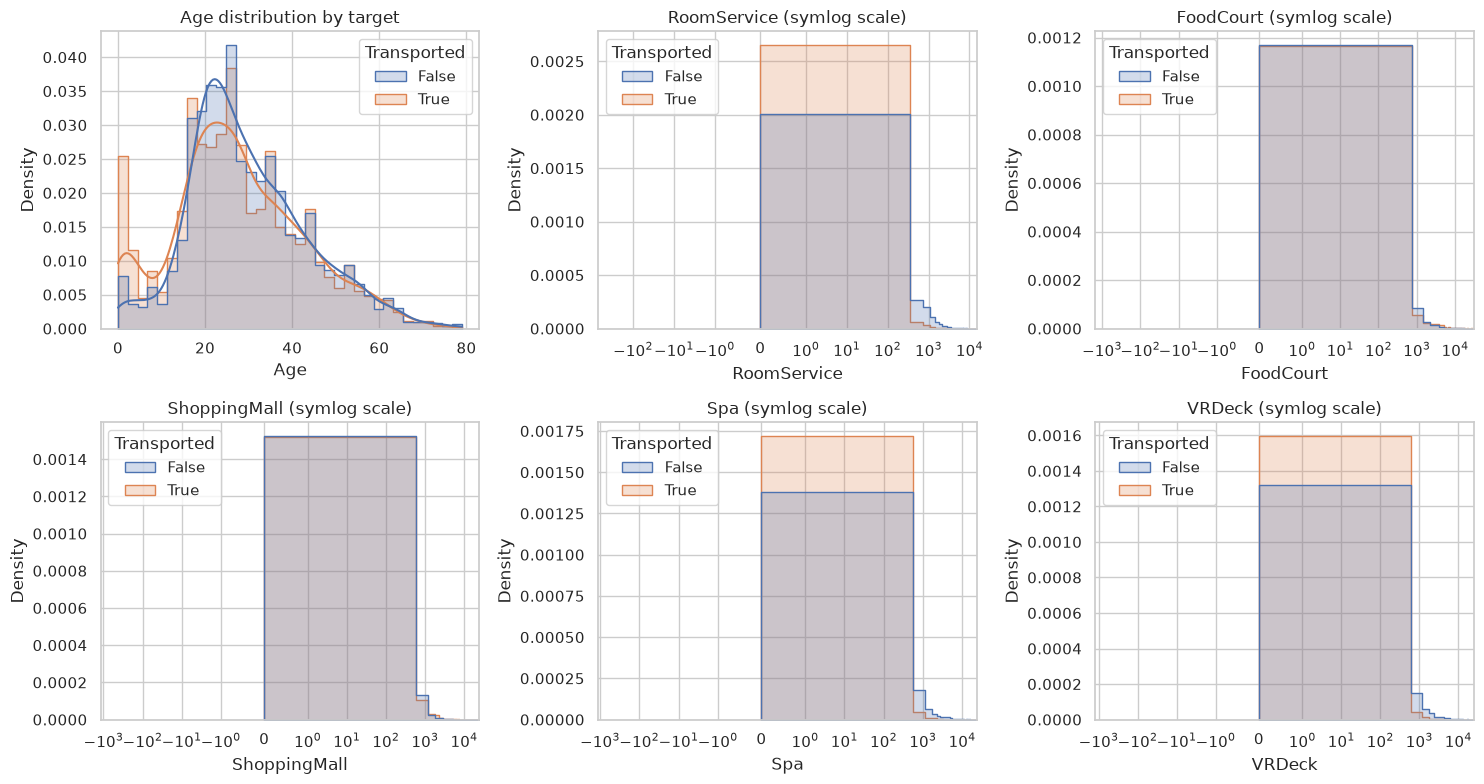

In [8]:
spend_columns = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.histplot(
    data=train_df, x="Age", hue="Transported", bins=35, kde=True,
    element="step", stat="density", common_norm=False, ax=axes[0, 0]
)
axes[0, 0].set_title("Age distribution by target")

for ax, column in zip(axes.flat[1:], spend_columns):
    sns.histplot(
        data=train_df, x=column, hue="Transported", bins=40,
        element="step", stat="density", common_norm=False, ax=ax
    )
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(f"{column} (symlog scale)")

plt.tight_layout()
plt.show()


## Check simple numeric correlations

Pearson correlations are only a quick directional check; they do not replace validation, especially for nonlinear effects and categories. Boolean fields are converted to numeric only for this exploratory table.


,correlation_with_transported
RoomService,-0.244611
Spa,-0.221131
VRDeck,-0.207075
Age,-0.075026
VIP,-0.037650
ShoppingMall,0.010141
FoodCourt,0.046566
CryoSleep,0.468645
Transported,1.000000


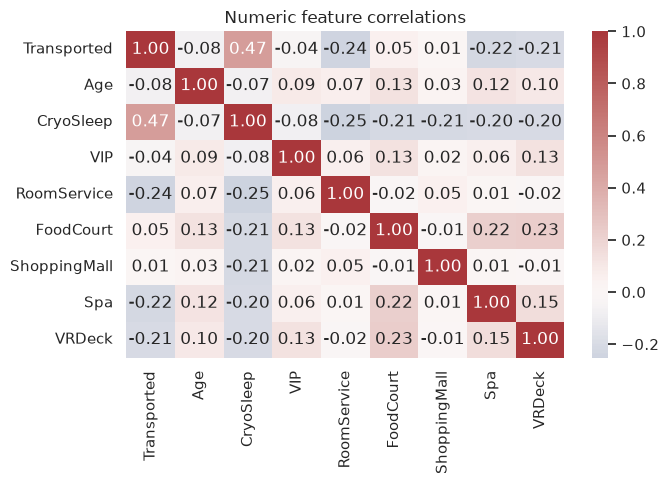

In [9]:
eda_numeric = train_df.copy()
eda_numeric["Transported"] = eda_numeric["Transported"].astype(int)
for column in ["CryoSleep", "VIP"]:
    eda_numeric[column] = eda_numeric[column].map({True: 1, False: 0})

correlation_columns = ["Transported", "Age", "CryoSleep", "VIP", *spend_columns]
correlations = (
    eda_numeric[correlation_columns]
    .corr(numeric_only=True)["Transported"]
    .sort_values()
)
display(correlations.to_frame("correlation_with_transported"))

plt.figure(figsize=(7, 5))
sns.heatmap(
    eda_numeric[correlation_columns].corr(numeric_only=True),
    cmap="vlag", center=0, annot=True, fmt=".2f"
)
plt.title("Numeric feature correlations")
plt.tight_layout()
plt.show()


## Engineer reusable passenger and group features

The feature function is deliberately self-contained so it can later move to `src/features.py`. Cabin, passenger group, surname, family size, total spend, cryosleep-spend contradictions, and age bands are extracted before the original identifier-like fields are removed.


In [10]:
SPEND_COLUMNS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
CATEGORICAL_FEATURES = [
    "HomePlanet", "CryoSleep", "Deck", "Side", "Destination",
    "VIP", "Surname", "AgeGroup"
]
NUMERIC_FEATURES = [
    "CabinNum", "GroupSize", "FamilySize", "Age", *SPEND_COLUMNS,
    "TotalSpend", "CryoSpendAnomaly"
]

def group_mode(series):
    """Return the deterministic modal non-null value, or NaN when none exists."""
    non_null = series.dropna()
    if non_null.empty:
        return np.nan
    modes = non_null.mode()
    return modes.iloc[0] if not modes.empty else np.nan

def fill_with_group_mode(frame, column, group_column="GroupId"):
    """Impute shared categorical properties from the travel group, then globally."""
    group_values = frame.groupby(group_column)[column].transform(group_mode)
    global_value = group_mode(frame[column])
    frame[column] = frame[column].fillna(group_values).fillna(global_value)

def fill_with_group_median(frame, column, group_column="GroupId"):
    """Impute numeric values from group medians, then the global median."""
    group_values = frame.groupby(group_column)[column].transform("median")
    global_value = frame[column].median()
    frame[column] = frame[column].fillna(group_values).fillna(global_value)

def engineer_features(raw_frame):
    """Create an all-imputed model matrix without target-dependent transformations."""
    frame = raw_frame.copy()

    cabin_parts = frame["Cabin"].str.split("/", expand=True)
    frame["Deck"] = cabin_parts[0]
    frame["CabinNum"] = pd.to_numeric(cabin_parts[1], errors="coerce")
    frame["Side"] = cabin_parts[2]

    passenger_parts = frame["PassengerId"].str.split("_", n=1, expand=True)
    frame["GroupId"] = passenger_parts[0]
    frame["GroupSize"] = frame.groupby("GroupId")["PassengerId"].transform("size")

    frame["Surname"] = frame["Name"].str.split().str[-1].fillna("Unknown")
    frame["FamilySize"] = frame.groupby(["GroupId", "Surname"])["PassengerId"].transform("size")

    observed_spend = frame[SPEND_COLUMNS].fillna(0).sum(axis=1)
    for column in ["HomePlanet", "Destination", "CryoSleep", "VIP", "Deck", "Side"]:
        fill_with_group_mode(frame, column)

    for column in ["Age", "CabinNum"]:
        fill_with_group_median(frame, column)

    # A cryosleep passenger with observed spending is a useful data-quality signal.
    frame["CryoSpendAnomaly"] = (
        frame["CryoSleep"].eq(True) & observed_spend.gt(0)
    ).astype("int8")

    # Missing spending for confirmed cryosleep passengers is structurally zero.
    for column in SPEND_COLUMNS:
        frame.loc[frame["CryoSleep"].eq(True) & frame[column].isna(), column] = 0
        fill_with_group_median(frame, column)

    frame["TotalSpend"] = frame[SPEND_COLUMNS].sum(axis=1)
    frame["AgeGroup"] = pd.cut(
        frame["Age"],
        bins=[-np.inf, 12, 17, 64, np.inf],
        labels=["child", "teen", "adult", "senior"]
    ).astype("object")

    model_frame = frame.drop(
        columns=["Name", "PassengerId", "Cabin", "GroupId", "Transported", "is_train"],
        errors="ignore"
    )
    return model_frame

combined_features = engineer_features(combined_raw)
assert combined_features.isna().sum().sum() == 0, "All model inputs must be imputed."
assert set(CATEGORICAL_FEATURES + NUMERIC_FEATURES).issubset(combined_features.columns)

X_train = combined_features.loc[combined_raw["is_train"]].reset_index(drop=True)
X_test = combined_features.loc[~combined_raw["is_train"]].reset_index(drop=True)
y_train = train_df["Transported"].astype(int).reset_index(drop=True)

print(f"Training feature matrix: {X_train.shape}")
print(f"Test feature matrix: {X_test.shape}")
display(X_train.head())


Training feature matrix: (8693, 19)
Test feature matrix: (4277, 19)


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNum,Side,GroupSize,Surname,FamilySize,CryoSpendAnomaly,TotalSpend,AgeGroup
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,B,0.0,P,1,Ofracculy,1,0,0.0,adult
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,F,0.0,S,1,Vines,1,0,736.0,adult
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,A,0.0,S,2,Susent,2,0,10383.0,adult
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,A,0.0,S,2,Susent,2,0,5176.0,adult
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,F,1.0,S,1,Santantines,1,0,1091.0,teen


## Why this imputation is structured this way

Passengers sharing a group often share origin, destination, cabin context, and related demographics. Categorical values therefore use the group mode then the dataset mode; numeric fields use the group median then the global median. Confirmed cryosleep passengers get zero only for *missing* spending, preserving actual contradictory spending as an anomaly feature. No row is removed.


In [11]:
imputation_audit = pd.DataFrame({
    "train_missing_after_engineering": X_train.isna().sum(),
    "test_missing_after_engineering": X_test.isna().sum(),
    "dtype": X_train.dtypes.astype(str),
})
display(imputation_audit)
assert imputation_audit["train_missing_after_engineering"].sum() == 0
assert imputation_audit["test_missing_after_engineering"].sum() == 0


,train_missing_after_engineering,test_missing_after_engineering,dtype
HomePlanet,0,0,str
CryoSleep,0,0,object
Destination,0,0,str
Age,0,0,float64
VIP,0,0,object
RoomService,0,0,float64
FoodCourt,0,0,float64
ShoppingMall,0,0,float64
Spa,0,0,float64
VRDeck,0,0,float64


## Prepare model-specific encodings

Tree models outside CatBoost receive one-hot encoded categorical fields, which makes nominal values usable without inventing an ordinal relationship. CatBoost receives the same engineered categorical values as strings and handles their encoding internally; this preserves a native categorical comparison.


In [12]:
def make_one_hot_encoder():
    """Support both newer and older scikit-learn OneHotEncoder APIs."""
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("categorical", make_one_hot_encoder(), CATEGORICAL_FEATURES),
            ("numeric", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )

def catboost_frame(frame):
    prepared = frame.copy()
    for column in CATEGORICAL_FEATURES:
        prepared[column] = prepared[column].astype(str)
    return prepared

X_train_cat = catboost_frame(X_train)
X_test_cat = catboost_frame(X_test)


## Fix the validation protocol

Every candidate uses this exact five-fold stratified split and `random_state=42`. That makes fold-level accuracy directly comparable and avoids a lucky split driving the model choice.


In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_train, y_train))

def score_summary(name, y_true, probabilities, splits):
    fold_scores = [
        accuracy_score(y_true.iloc[valid_idx], (probabilities[valid_idx] >= 0.5).astype(int))
        for _, valid_idx in splits
    ]
    mean_score = float(np.mean(fold_scores))
    std_score = float(np.std(fold_scores))
    print(f"{name} CV accuracy: {mean_score:.4f} +/- {std_score:.4f}")
    print("Fold accuracies:", [round(score, 4) for score in fold_scores])
    return {"name": name, "fold_scores": fold_scores, "mean": mean_score, "std": std_score,
            "oof_probabilities": probabilities}


## Establish the benchmark

Extra Trees is a fast, robust baseline for nonlinear tabular data. Its deliberately conservative configuration is the score stronger models must beat, rather than a model optimized through extensive search.


In [14]:
def make_extra_trees_pipeline():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", ExtraTreesClassifier(
            n_estimators=400,
            min_samples_leaf=2,
            max_features="sqrt",
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ])

def evaluate_sklearn_model(name, pipeline_factory, features, target, splits):
    oof_probabilities = np.zeros(len(features), dtype=float)
    for fold, (train_idx, valid_idx) in enumerate(splits, start=1):
        model = pipeline_factory()
        model.fit(features.iloc[train_idx], target.iloc[train_idx])
        oof_probabilities[valid_idx] = model.predict_proba(features.iloc[valid_idx])[:, 1]
        print(f"{name}: completed fold {fold}/5")
    return score_summary(name, target, oof_probabilities, splits)

model_results = {}
model_results["Extra Trees baseline"] = evaluate_sklearn_model(
    "Extra Trees baseline", make_extra_trees_pipeline, X_train, y_train, cv_splits
)


Extra Trees baseline: completed fold 1/5
Extra Trees baseline: completed fold 2/5
Extra Trees baseline: completed fold 3/5
Extra Trees baseline: completed fold 4/5
Extra Trees baseline: completed fold 5/5
Extra Trees baseline CV accuracy: 0.7595 +/- 0.0094
Fold accuracies: [0.7746, 0.7522, 0.7665, 0.7514, 0.7526]


## Compare lightly tuned gradient boosting models

These settings add modest regularization and restrained tree complexity, rather than a large hyperparameter search. The aim is a stable validation improvement that should generalize on this relatively small competition dataset.


In [15]:
def make_xgboost_pipeline():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", XGBClassifier(
            n_estimators=350,
            max_depth=4,
            learning_rate=0.035,
            subsample=0.85,
            colsample_bytree=0.85,
            min_child_weight=3,
            reg_lambda=2.0,
            eval_metric="logloss",
            n_jobs=-1,
            random_state=RANDOM_STATE,
            tree_method="hist",
        )),
    ])

def make_lightgbm_pipeline():
    return Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", LGBMClassifier(
            n_estimators=350,
            learning_rate=0.03,
            num_leaves=15,
            min_child_samples=30,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=1.0,
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbosity=-1,
        )),
    ])

model_results["XGBoost"] = evaluate_sklearn_model(
    "XGBoost", make_xgboost_pipeline, X_train, y_train, cv_splits
)
model_results["LightGBM"] = evaluate_sklearn_model(
    "LightGBM", make_lightgbm_pipeline, X_train, y_train, cv_splits
)


XGBoost: completed fold 1/5
XGBoost: completed fold 2/5
XGBoost: completed fold 3/5
XGBoost: completed fold 4/5
XGBoost: completed fold 5/5
XGBoost CV accuracy: 0.8080 +/- 0.0059
Fold accuracies: [0.8154, 0.8028, 0.8016, 0.8147, 0.8055]
LightGBM: completed fold 1/5
LightGBM: completed fold 2/5
LightGBM: completed fold 3/5
LightGBM: completed fold 4/5
LightGBM: completed fold 5/5
LightGBM CV accuracy: 0.8094 +/- 0.0068
Fold accuracies: [0.8074, 0.8016, 0.8143, 0.8199, 0.8038]


## Evaluate CatBoost with native categorical handling

CatBoost can model the categorical fields directly, so it is assessed separately on the exact same folds. Its controlled iteration count, depth, learning rate, and L2 regularization prioritize generalization over squeezing the training set.


In [16]:
def make_catboost_model():
    return CatBoostClassifier(
        iterations=400,
        depth=6,
        learning_rate=0.04,
        l2_leaf_reg=5.0,
        loss_function="Logloss",
        eval_metric="Accuracy",
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1,
    )

def evaluate_catboost(features, target, splits):
    oof_probabilities = np.zeros(len(features), dtype=float)
    for fold, (train_idx, valid_idx) in enumerate(splits, start=1):
        model = make_catboost_model()
        model.fit(
            features.iloc[train_idx],
            target.iloc[train_idx],
            cat_features=CATEGORICAL_FEATURES,
        )
        oof_probabilities[valid_idx] = model.predict_proba(features.iloc[valid_idx])[:, 1]
        print(f"CatBoost: completed fold {fold}/5")
    return score_summary("CatBoost", target, oof_probabilities, splits)

model_results["CatBoost"] = evaluate_catboost(X_train_cat, y_train, cv_splits)

cv_comparison = (
    pd.DataFrame([
        {"Model": result["name"], "CV accuracy": result["mean"], "CV std": result["std"]}
        for result in model_results.values()
    ])
    .sort_values("CV accuracy", ascending=False)
    .reset_index(drop=True)
)
display(cv_comparison.style.format({"CV accuracy": "{:.4f}", "CV std": "{:.4f}"}))


CatBoost: completed fold 1/5
CatBoost: completed fold 2/5
CatBoost: completed fold 3/5
CatBoost: completed fold 4/5
CatBoost: completed fold 5/5
CatBoost CV accuracy: 0.8140 +/- 0.0043
Fold accuracies: [0.8108, 0.8097, 0.8177, 0.8205, 0.8113]


,Model,CV accuracy,CV std
0,CatBoost,0.8140,0.0043
1,LightGBM,0.8094,0.0068
2,XGBoost,0.8080,0.0059
3,Extra Trees baseline,0.7595,0.0094


## Test a simple probability blend

Averaging the out-of-fold probabilities from the three best individual models reduces model-specific variance without tuning blend weights. The blend is retained only if its five-fold accuracy exceeds the strongest single model.


In [17]:
ranked_model_names = sorted(
    model_results,
    key=lambda name: model_results[name]["mean"],
    reverse=True
)
blend_model_names = ranked_model_names[:3]
blend_oof_probabilities = np.mean(
    [model_results[name]["oof_probabilities"] for name in blend_model_names],
    axis=0,
)
blend_result = score_summary(
    f"Mean blend ({', '.join(blend_model_names)})",
    y_train,
    blend_oof_probabilities,
    cv_splits,
)

best_single_name = ranked_model_names[0]
best_single_result = model_results[best_single_name]
use_blend = blend_result["mean"] > best_single_result["mean"]
final_strategy = "blend" if use_blend else "single model"

print(f"Best single model: {best_single_name} ({best_single_result['mean']:.4f})")
print(f"Blend score: {blend_result['mean']:.4f}")
print(f"Selected final strategy: {final_strategy}")


Mean blend (CatBoost, LightGBM, XGBoost) CV accuracy: 0.8094 +/- 0.0029
Fold accuracies: [0.8114, 0.8051, 0.8114, 0.8124, 0.8067]
Best single model: CatBoost (0.8140)
Blend score: 0.8094
Selected final strategy: single model


## Inspect what mattered

Feature importance is calculated for the best individual model, which remains interpretable even if the final decision uses a blend. Importance measures relative predictive usage, not causality; correlated inputs can divide credit among themselves.


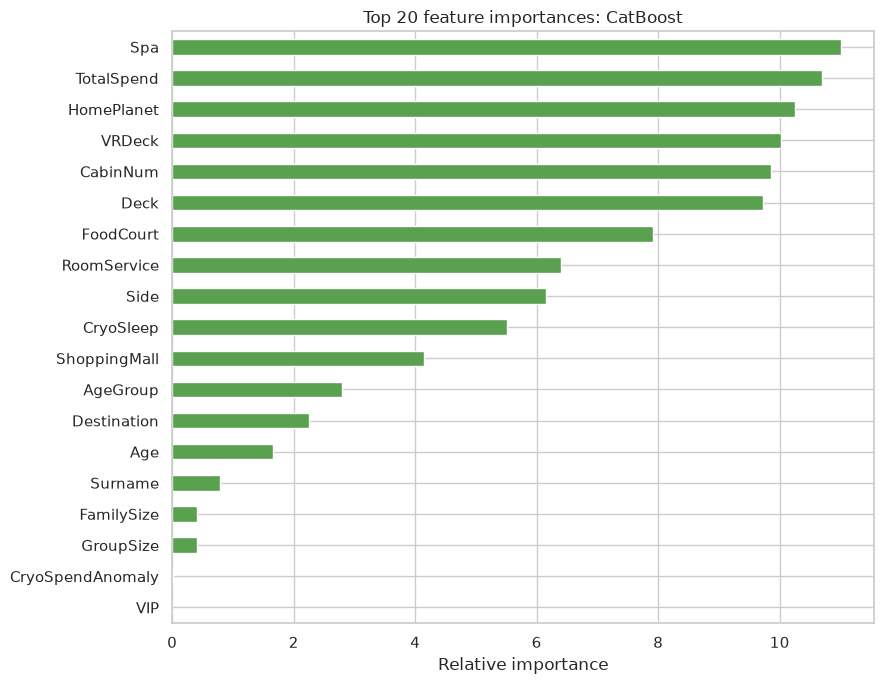

,importance
Spa,11.001917
TotalSpend,10.692515
HomePlanet,10.256237
VRDeck,10.022120
CabinNum,9.858737
Deck,9.717377
FoodCourt,7.908836
RoomService,6.393834
Side,6.150245
CryoSleep,5.517551


In [18]:
SKLEARN_FACTORIES = {
    "Extra Trees baseline": make_extra_trees_pipeline,
    "XGBoost": make_xgboost_pipeline,
    "LightGBM": make_lightgbm_pipeline,
}

def fit_best_single_model(model_name):
    if model_name == "CatBoost":
        model = make_catboost_model()
        model.fit(X_train_cat, y_train, cat_features=CATEGORICAL_FEATURES)
        return model, pd.Series(
            model.get_feature_importance(),
            index=X_train_cat.columns,
            name="importance"
        ).sort_values(ascending=False)

    pipeline = SKLEARN_FACTORIES[model_name]()
    pipeline.fit(X_train, y_train)
    feature_names = pipeline.named_steps["preprocessor"].get_feature_names_out()
    importances = pipeline.named_steps["model"].feature_importances_
    return pipeline, pd.Series(importances, index=feature_names, name="importance").sort_values(ascending=False)

importance_model, feature_importance = fit_best_single_model(best_single_name)
top_importance = feature_importance.head(20).sort_values()

plt.figure(figsize=(9, 7))
top_importance.plot(kind="barh", color="#59A14F")
plt.title(f"Top 20 feature importances: {best_single_name}")
plt.xlabel("Relative importance")
plt.tight_layout()
plt.show()

display(feature_importance.head(20).to_frame())


## Select the final estimator from validation

The cell below records the decision after all cross-validation results are available. A blend is used only when its out-of-fold accuracy is higher than the best individual model; otherwise the best single model is favored for its simpler deployment path.


In [19]:
if use_blend:
    print(
        f"Final selection: mean probability blend of {', '.join(blend_model_names)}. "
        f"It scored {blend_result['mean']:.4f} CV accuracy, above the best single "
        f"model ({best_single_name}: {best_single_result['mean']:.4f})."
    )
else:
    print(
        f"Final selection: {best_single_name}. It scored "
        f"{best_single_result['mean']:.4f} CV accuracy, at least as high as the "
        f"blend ({blend_result['mean']:.4f})."
    )

print("\nHighest-importance engineered features:")
print(", ".join(feature_importance.head(8).index.tolist()))


Final selection: CatBoost. It scored 0.8140 CV accuracy, at least as high as the blend (0.8094).

Highest-importance engineered features:
Spa, TotalSpend, HomePlanet, VRDeck, CabinNum, Deck, FoodCourt, RoomService


## Refit on all labeled rows and create the Kaggle submission

The selected model or blend is now trained on every available labeled passenger, predicts every test passenger, and writes the exact two-column schema required by `sample_submission.csv` to the project submissions directory.


In [21]:
def fit_predict_sklearn(model_name):
    model = SKLEARN_FACTORIES[model_name]()
    model.fit(X_train, y_train)
    return model.predict_proba(X_test)[:, 1]

def fit_predict_catboost():
    model = make_catboost_model()
    model.fit(X_train_cat, y_train, cat_features=CATEGORICAL_FEATURES)
    return model.predict_proba(X_test_cat)[:, 1]

def fit_predict_full(model_name):
    if model_name == "CatBoost":
        return fit_predict_catboost()
    return fit_predict_sklearn(model_name)

if use_blend:
    test_probabilities = np.mean(
        [fit_predict_full(model_name) for model_name in blend_model_names],
        axis=0,
    )
else:
    test_probabilities = fit_predict_full(best_single_name)

submission = pd.DataFrame({
    "PassengerId": test_passenger_ids,
    "Transported": (test_probabilities >= 0.5),
})

assert len(submission) == len(test_df)
assert submission.columns.tolist() == sample_submission.columns.tolist()
assert submission["PassengerId"].equals(sample_submission["PassengerId"])

SUBMISSION_PATH = SUBMISSION_DIR / "submission_kenga.csv"
submission.to_csv(SUBMISSION_PATH, index=False)

print(f"Saved {len(submission):,} predictions to: {SUBMISSION_PATH}")
display(submission.head())
display(submission["Transported"].value_counts(normalize=True).rename("proportion").to_frame())


Saved 4,277 predictions to: /workspaces/alpha-centauri-rescue/submissions/submission_kenga.csv


,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,False


,proportion
Transported,
True,0.514847
False,0.485153
